# โครงงานเสนอ DLT Brand and Vehicle Type Demand Analysis

**สถานะ:** ข้อเสนอพร้อมผลคำนวณจริง สมาชิกกลุ่ม 2–5 คน การตรวจหัวข้อ/ชุดข้อมูลไม่ซ้ำ และการอนุมัติหัวข้อยังรอดำเนินการ ไม่มีการสมมติชื่อสมาชิกหรืออ้างว่าได้รับอนุมัติแล้ว

วัตถุประสงค์: สนับสนุนการวางแผนตามยี่ห้อและประเภทรถ ใช้ยอดจดทะเบียนเป็นตัวชี้วัดการจดทะเบียน ไม่เรียกว่ายอดขายหรืออุปสงค์ทั้งหมด และไม่สรุปเหตุและผลจากข้อมูลนี้

รันซ้ำ: ติดตั้ง `requirements.txt` ใน Python 3.11 วาง notebook ร่วมกับ raw CSV และ `term_project.py` จากนั้น Restart Kernel / Run All หรือรัน `python build_notebook.py`

## 1 โหลดและตรวจข้อมูลจริง
แหล่งตรวจสอบกรมการขนส่งทางบก: [DLT Data Catalog](https://gdcatalog.dlt.go.th/en/dataset/stat_1_1_01_first_regis_vehicles_car). สำเนา CSV นี้มาจากไฟล์ที่ได้รับในวิชา เก็บ hash เพื่อยืนยันไฟล์ที่ใช้จริง ไม่ได้ดาวน์โหลดข้อมูลใหม่มาปะปน

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
from IPython.display import display, Image, FileLink
from term_project import *
folder=Path.cwd()
if not (folder/RAW_NAME).exists(): folder=folder/'BI Term Project'
raw=pd.read_csv(folder/RAW_NAME,encoding='utf-8-sig')
assert raw.shape==(68398,9)
print('Raw shape',raw.shape)
print('Missing values',raw.isna().sum().to_dict())
print('Exact duplicates',raw.duplicated().sum())
display(raw.head())

Raw shape (68398, 9)
Missing values {'ปี พ.ศ.': 0, 'เดือน': 0, 'ประเภทรถ': 0, 'ยี่ห้อ': 0, 'รุ่น': 623, 'จำนวน': 0, 'Source_Year_BE': 0, 'Source_Month': 0, 'Source_File': 0}
Exact duplicates 0


,ปี พ.ศ.,เดือน,ประเภทรถ,ยี่ห้อ,รุ่น,จำนวน,Source_Year_BE,Source_Month,Source_File
0,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A4 AV 45 TFSI q S line BE,1,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
1,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 CP 40 TFSI S line,15,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
2,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 CP 45 TFSI q S line BE,8,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
3,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 SB 40 TFSI S line,22,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
4,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 SB 45 TFSI q S line BE,4,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv


## 2 ETL และตรวจ 25 เดือนต่อเนื่อง
ข้อกำหนด 24 เดือนผ่านจาก Jan2024–Jan2026 จำนวน25เดือน February2026 มี6records18คันและยังไม่ครบ จึงตัดออกจากactual ห้ามเติมDecember2023โดยเดา รุ่นที่ขาด623recordsเก็บไว้เป็นUnknown model ไม่ตัดยอดตามยี่ห้อ/ประเภทรถ

In [2]:
fact,quality,etl=prepare_fact(raw)
print('Fact rows',len(fact),'Complete months',fact.Date.nunique())
print('Complete-window source records',fact.SourceRecords.sum())
print('Registrations',fact.Registrations.sum())
assert fact.Date.nunique()==25
assert fact.SourceRecords.sum()==35805
assert fact.Registrations.sum()==5007659
display(etl)
display(quality.tail())
display(fact.head())

Fact rows 5712 Complete months 25
Complete-window source records 35805
Registrations 5007659


,Stage,InputRows,OutputRows,Reason
0,Raw read,68398,68398,Original retained without modification
1,Type validation and normalize labels,68398,68398,Validate counts/period and trim labels; missin...
2,Complete consecutive period,68398,35805,Jan 2024-Jan 2026; exclude earlier discontinuo...
3,Monthly brand vehicle type fact,35805,5712,Sum registrations at Date Brand VehicleType gr...


,Date,SourceRegistrations,SourceRecords,IsComplete,UsedForModeling
44,2025-10-01,185344,1474,True,True
45,2025-11-01,177066,1414,True,True
46,2025-12-01,184093,1404,True,True
47,2026-01-01,250212,1421,True,True
48,2026-02-01,18,6,False,False


,Date,Brand,VehicleType,Registrations,SourceRecords
0,2024-01-01,AIMA,รถจักรยานยนต์,2,1
1,2024-01-01,AION,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,185,2
2,2024-01-01,AION,รถยนต์รับจ้างบรรทุกคนโดยสารไม่เกิน 7 คน,89,1
3,2024-01-01,AJ,รถจักรยานยนต์,174,5
4,2024-01-01,ALPHA VOLANTIS,รถจักรยานยนต์,7,2


## 3 อนุกรมยอดรวม ยี่ห้อ และประเภทรถ
เลือก top3brands และ top3types จาก Jan2024–Mar2025 เท่านั้น ไม่ใช้ช่วงvalidation/testเลือกsegment เดือนที่ไฟล์รวมครบแต่ไม่มียี่ห้อนั้นให้0เพื่อระบุว่าไม่มีrecordsของcategory ไม่ได้ใช้0แทนเดือนที่sourceหายหรือไม่ครบ

In [3]:
def segment_series(fact, kind, name):
    if kind=='Total':
        selected=fact
    else:
        selected=fact[fact[kind]==name]
    values=selected.groupby('Date').Registrations.sum().reindex(DATES,fill_value=0)
    # Zero means no records for this category inside a verified complete source month.
    return values.rename('Registrations').reset_index().rename(columns={'index':'Date'})

def choose_series(fact):
    past=fact[fact.Date<='2025-03-01']
    series=[('Total','All')]
    for kind in ['Brand','VehicleType']:
        names=past.groupby(kind).Registrations.sum().sort_values(ascending=False).head(3).index
        series.extend((kind,name) for name in names)
    return series

series_list=choose_series(fact)
display(pd.DataFrame(series_list,columns=['SegmentType','SegmentName']))
display(segment_series(fact,'Brand','HONDA').head())

,SegmentType,SegmentName
0,Total,All
1,Brand,HONDA
2,Brand,TOYOTA
3,Brand,YAMAHA
4,VehicleType,รถจักรยานยนต์
5,VehicleType,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน
6,VehicleType,รถยนต์บรรทุกส่วนบุคคล


,Date,Registrations
0,2024-01-01,135987
1,2024-02-01,126394
2,2024-03-01,131200
3,2024-04-01,110792
4,2024-05-01,143651


## 4 Lag และ Train Validation Test
22observationsแบ่ง12/5/5: Train Apr2024–Mar2025; Validation Apr–Aug2025; Test Sep2025–Jan2026 ห้ามshuffle เลือกโมเดลจากvalidationMAEก่อนเปิดผลtest การทดสอบเป็นrollingone-month-aheadโดยใช้ยอดจริงเดือนก่อนที่ทราบแล้วเป็นLag เพิ่มMonthSin/MonthCosกับTimeIndexที่ทราบจากปฏิทิน

In [4]:
def prepare_modeling(series):
    if series.Date.tolist()!=DATES.tolist():
        raise ValueError('Need 25 continuous complete source months')
    data=series.copy()
    for lag in range(1,4):
        data[f'Lag{lag}']=data.Registrations.shift(lag)
    data['MonthSin']=np.sin(2*np.pi*data.Date.dt.month/12)
    data['MonthCos']=np.cos(2*np.pi*data.Date.dt.month/12)
    data['TimeIndex']=np.arange(len(data))
    data=data.dropna().reset_index(drop=True)
    return data,data.iloc[:12].copy(),data.iloc[12:17].copy(),data.iloc[17:].copy()

model_data,train,validation,test=prepare_modeling(segment_series(fact,'Total','All'))
assert [len(model_data),len(train),len(validation),len(test)]==[22,12,5,5]
for name,frame in [('Train',train),('Validation',validation),('Test',test)]: print(name,frame.Date.min(),frame.Date.max(),len(frame))
display(model_data.head())

Train 2024-04-01 00:00:00 2025-03-01 00:00:00 12
Validation 2025-04-01 00:00:00 2025-08-01 00:00:00 5
Test 2025-09-01 00:00:00 2026-01-01 00:00:00 5


,Date,Registrations,Lag1,Lag2,Lag3,MonthSin,MonthCos,TimeIndex
0,2024-04-01,181314,214311.0,208918.0,239866.0,8.660254e-01,-0.500000,3
1,2024-05-01,227170,181314.0,214311.0,208918.0,5.000000e-01,-0.866025,4
2,2024-06-01,211518,227170.0,181314.0,214311.0,1.224647e-16,-1.000000,5
3,2024-07-01,200405,211518.0,227170.0,181314.0,-5.000000e-01,-0.866025,6
4,2024-08-01,187264,200405.0,211518.0,227170.0,-8.660254e-01,-0.500000,7


## 5 เปรียบเทียบ4อัลกอริทึมพร้อมNaivebaseline
LinearRegression, Ridge, RandomForest, GradientBoosting พารามิเตอร์กำหนดไว้ล่วงหน้า ไม่ปรับจากtest ทำStandardScalerเฉพาะข้อมูลฝึกภายในpipeline ผลทำนายติดลบถูกclipเป็น0เหมือนกันทั้งvalidation/test/future หลังเลือกโมเดล refittrain+validation17แถวเพื่อประเมินtest แล้วrefit22แถวเพื่อforecastFeb2026

In [5]:
def make_models():
    return {
        'Linear Regression':make_pipeline(StandardScaler(),LinearRegression()),
        'Ridge Regression':make_pipeline(StandardScaler(),Ridge(alpha=10.0)),
        'Random Forest':RandomForestRegressor(n_estimators=200,max_depth=3,min_samples_leaf=2,random_state=42),
        'Gradient Boosting':GradientBoostingRegressor(n_estimators=200,learning_rate=.03,max_depth=2,random_state=42),
    }

def select_model(results):
    return results.sort_values('ValidationMAE',kind='stable').iloc[0].Model

run=main()
comparison=pd.read_csv(folder/'ModelComparison.csv')
forecast=pd.read_csv(folder/'FactForecast.csv',parse_dates=['Date'])
display(comparison[comparison.SelectedModel])
display(forecast[forecast.DatasetSegment=='Future'])

SegmentType                     SegmentName             Model  ValidationMAE      TestMAE     TestRMSE    TestR2
      Total                             All Gradient Boosting    9436.512806 16207.591882 20334.013672  0.425729
      Brand                           HONDA     Random Forest    6645.184970  4461.943180  5153.542363  0.578394
      Brand                          TOYOTA  Ridge Regression     673.663292  2331.192061  3009.207740  0.159839
      Brand                          YAMAHA Gradient Boosting    2080.599482  1255.654123  1559.641264 -0.559295
VehicleType                   รถจักรยานยนต์     Random Forest    8718.210522  5760.648681  6776.973562  0.315827
VehicleType รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน  Ridge Regression    3521.685428  9857.362626 19228.997774 -0.155278
VehicleType           รถยนต์บรรทุกส่วนบุคคล    Naive Forecast     338.200000   749.800000   964.715398 -0.722060
SegmentType                     SegmentName  ForecastRegistrations             Model
      Total

,SeriesKey,SegmentType,SegmentName,Model,ValidationMAE,ValidationRMSE,ValidationR2,TestMAE,TestRMSE,TestR2,SelectedModel
0,S01,Total,All,Gradient Boosting,9436.512806,10404.838103,0.636728,16207.591882,20334.013672,0.425729,True
5,S02,Brand,HONDA,Random Forest,6645.184970,7573.577090,0.573948,4461.943180,5153.542363,0.578394,True
10,S03,Brand,TOYOTA,Ridge Regression,673.663292,801.798581,0.082927,2331.192061,3009.207740,0.159839,True
15,S04,Brand,YAMAHA,Gradient Boosting,2080.599482,2626.203428,-0.375107,1255.654123,1559.641264,-0.559295,True
20,S05,VehicleType,รถจักรยานยนต์,Random Forest,8718.210522,9736.659381,0.453405,5760.648681,6776.973562,0.315827,True
25,S06,VehicleType,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,Ridge Regression,3521.685428,3813.008059,-0.357386,9857.362626,19228.997774,-0.155278,True
30,S07,VehicleType,รถยนต์บรรทุกส่วนบุคคล,Naive Forecast,338.200000,450.564757,-3.743413,749.800000,964.715398,-0.722060,True


,SeriesKey,SegmentType,SegmentName,Date,ActualRegistrations,ForecastRegistrations,DatasetSegment,Model
25,S01,Total,All,2026-02-01,NaN,227934.333617,Future,Gradient Boosting
51,S02,Brand,HONDA,2026-02-01,NaN,128384.546438,Future,Random Forest
77,S03,Brand,TOYOTA,2026-02-01,NaN,19006.418585,Future,Ridge Regression
103,S04,Brand,YAMAHA,2026-02-01,NaN,18789.232831,Future,Gradient Boosting
129,S05,VehicleType,รถจักรยานยนต์,2026-02-01,NaN,147212.763370,Future,Random Forest
155,S06,VehicleType,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,2026-02-01,NaN,41273.698021,Future,Ridge Regression
181,S07,VehicleType,รถยนต์บรรทุกส่วนบุคคล,2026-02-01,NaN,6312.000000,Future,Naive Forecast


## 6 สมมติฐานและหลักฐานจริง
6คำถามมีเกณฑ์ชัดเจน เป็นการประเมินเชิงพรรณนาบนrecordsที่ได้รับ ไม่มีการอ้างp-valueหรือเหตุและผล H3เมื่อผลจริงเพิ่มขึ้นต้องปฏิเสธสมมติฐานลดลง

In [6]:
hypotheses=pd.read_csv(folder/'HypothesisEvidence.csv')
display(hypotheses)
errors=pd.read_csv(folder/'TestErrors.csv',parse_dates=['Date'])
display(errors.sort_values('AbsoluteError',ascending=False).head(10))

,Hypothesis,Question,ObservedValue,Threshold,Result,Interpretation
0,H1,Motorcycles exceed 50 percent of registrations...,0.723830,0.5,Supported descriptively,"Registration composition, not sales or causal ..."
1,H2,Honda is the largest brand overall in 2024-2025,0.617623,0.0,Supported descriptively,Overall brand composition mixes motorcycles an...
2,H3,Private passenger car registrations declined i...,0.039995,0.0,Not supported descriptively,Like-for-like full calendar years within passe...
3,H4,The largest 3 brands account for over 70 perce...,0.814304,0.7,Supported descriptively,Full-period concentration is descriptive; pred...
4,H5,January 2026 registrations exceed January 2025,0.097903,0.0,Supported descriptively,A one-month year-on-year change does not prove...
5,H6,The validation-selected total model beats Naiv...,0.110030,0.0,Supported descriptively,Test is reporting-only; a negative improvement...


,SeriesKey,SegmentType,SegmentName,Date,ActualRegistrations,PredictedRegistrations,AbsoluteError,Model
29,S06,VehicleType,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,2026-01-01,83281,40445.421636,42835.578364,Ridge Regression
4,S01,Total,All,2026-01-01,250212,213296.675515,36915.324485,Gradient Boosting
0,S01,Total,All,2025-09-01,188713,169523.226067,19189.773933,Gradient Boosting
3,S01,Total,All,2025-12-01,184093,167494.151094,16598.848906,Gradient Boosting
22,S05,VehicleType,รถจักรยานยนต์,2025-11-01,129640,140965.472732,11325.472732,Random Forest
23,S05,VehicleType,รถจักรยานยนต์,2025-12-01,138046,145953.502038,7907.502038,Random Forest
2,S01,Total,All,2025-11-01,177066,184847.026724,7781.026724,Gradient Boosting
7,S02,Brand,HONDA,2025-11-01,111777,119009.084905,7232.084905,Random Forest
8,S02,Brand,HONDA,2025-12-01,115753,122840.269107,7087.269107,Random Forest
14,S03,Brand,TOYOTA,2026-01-01,23592,18404.114349,5187.885651,Ridge Regression


## 7 กราฟจริงและความแตกต่างระหว่างsegment
ยอดรวม/ยี่ห้อ/ประเภทรถเป็นมุมมองซ้อนกัน ห้ามบวกforecastทั้ง7seriesเป็นยอดรวมของประเทศ ภาพกราฟนี้ยังไม่ใช่ภาพPowerBI

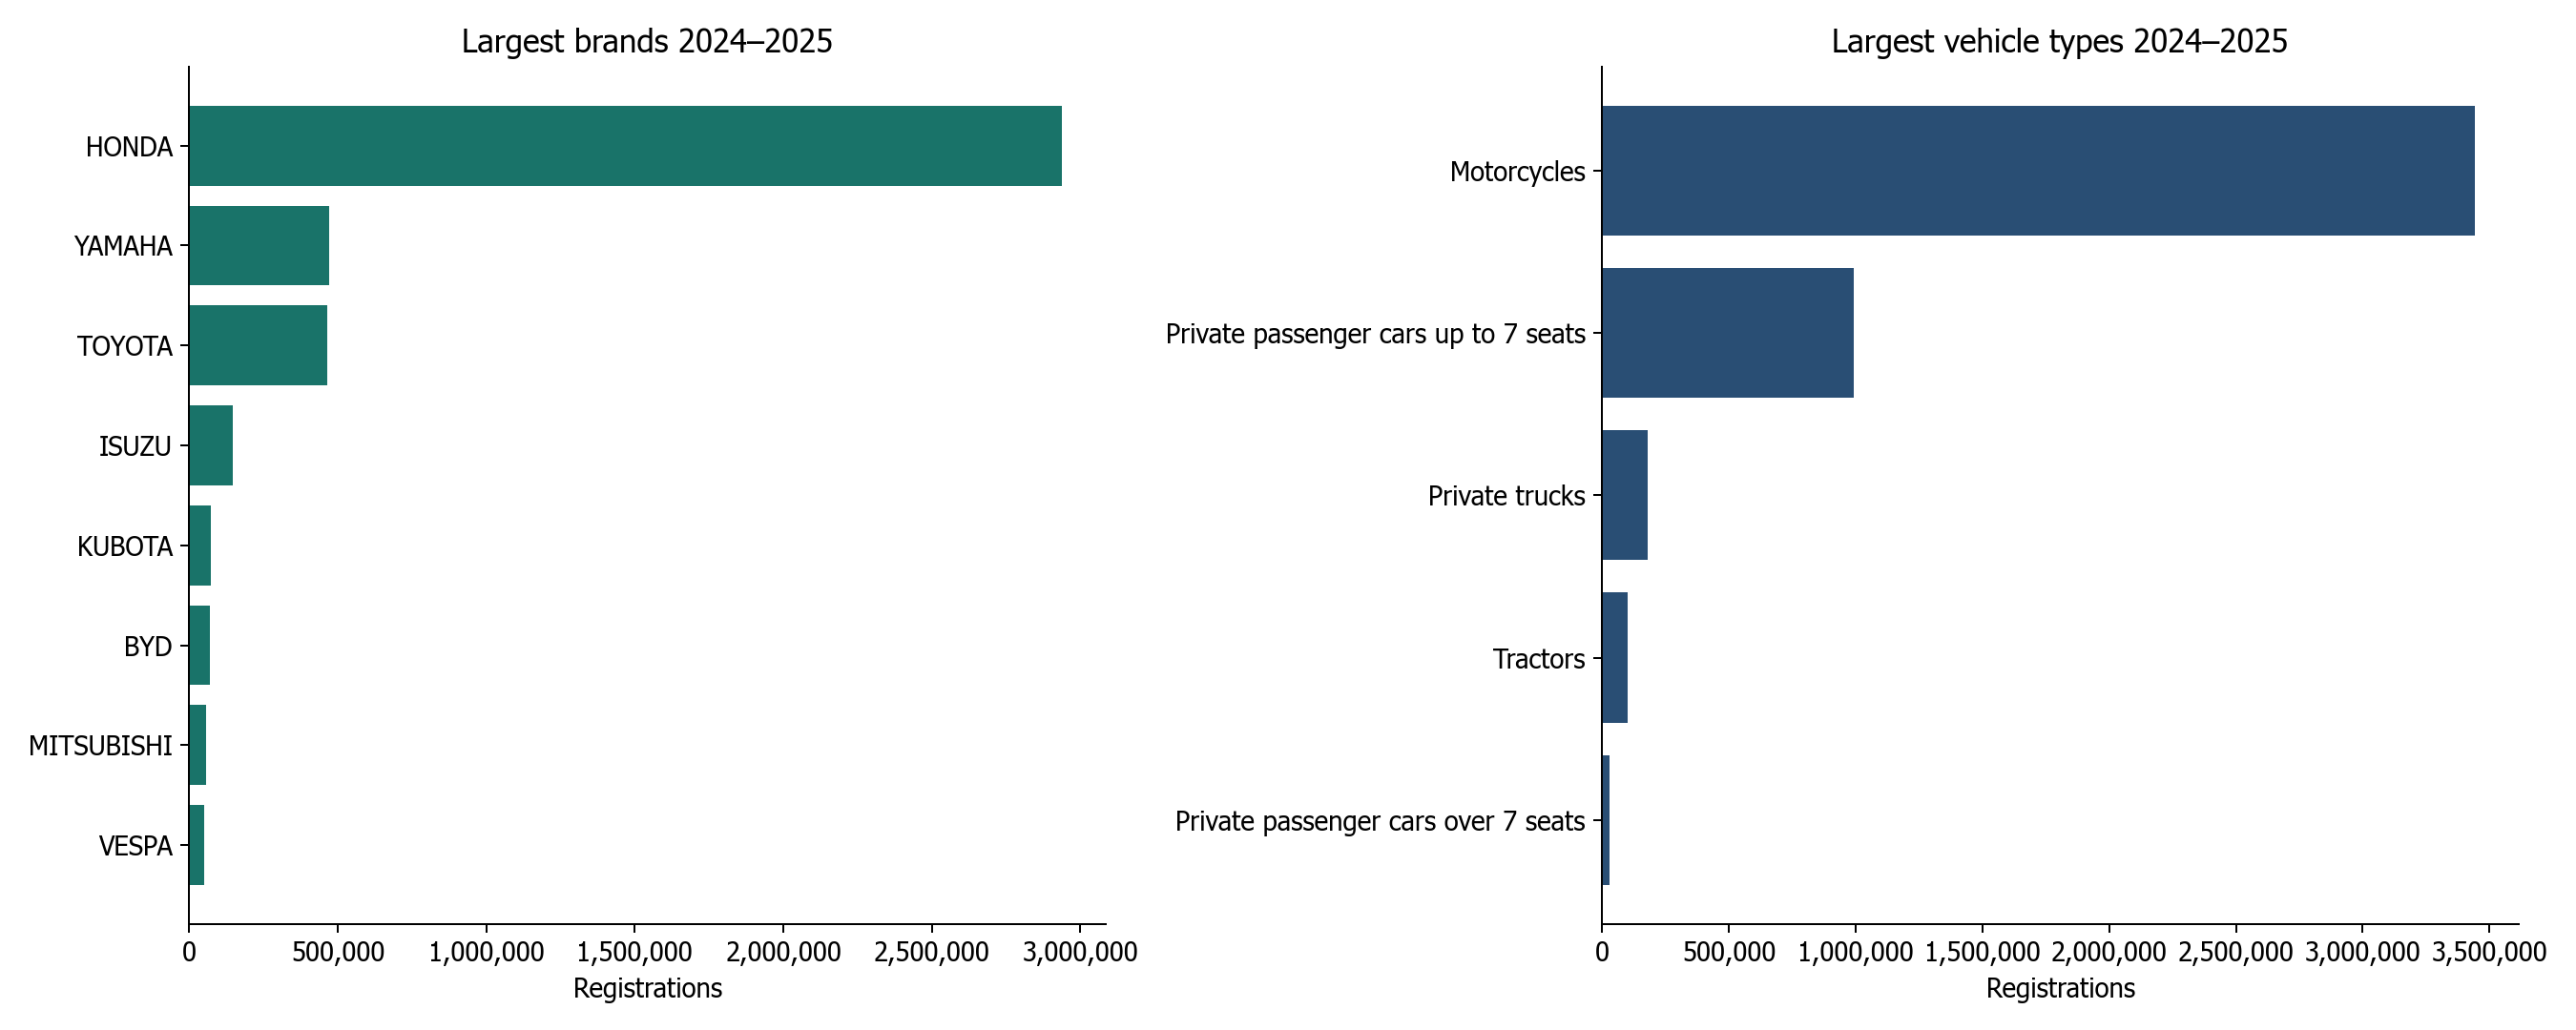

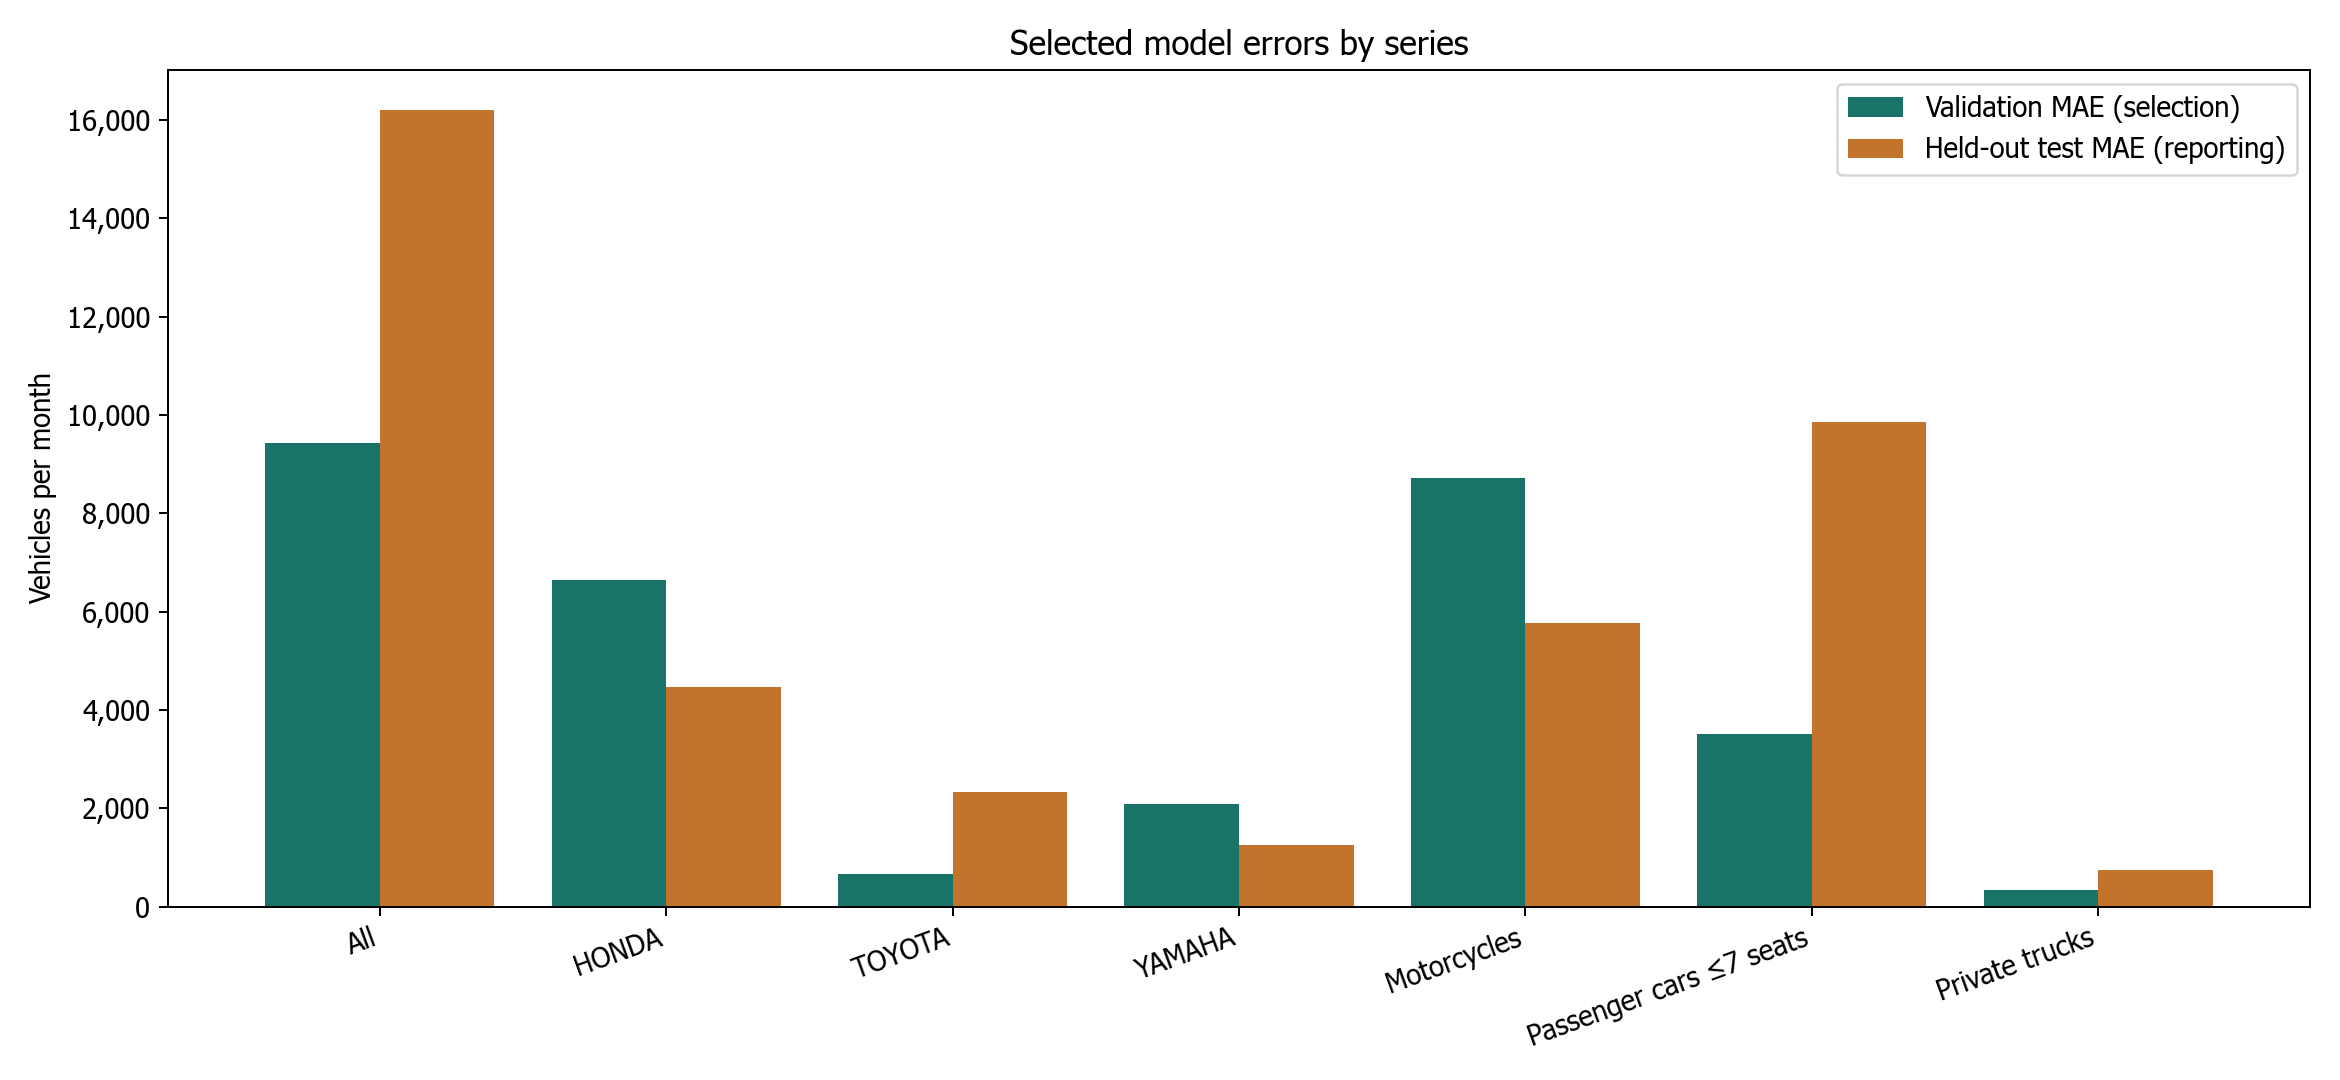

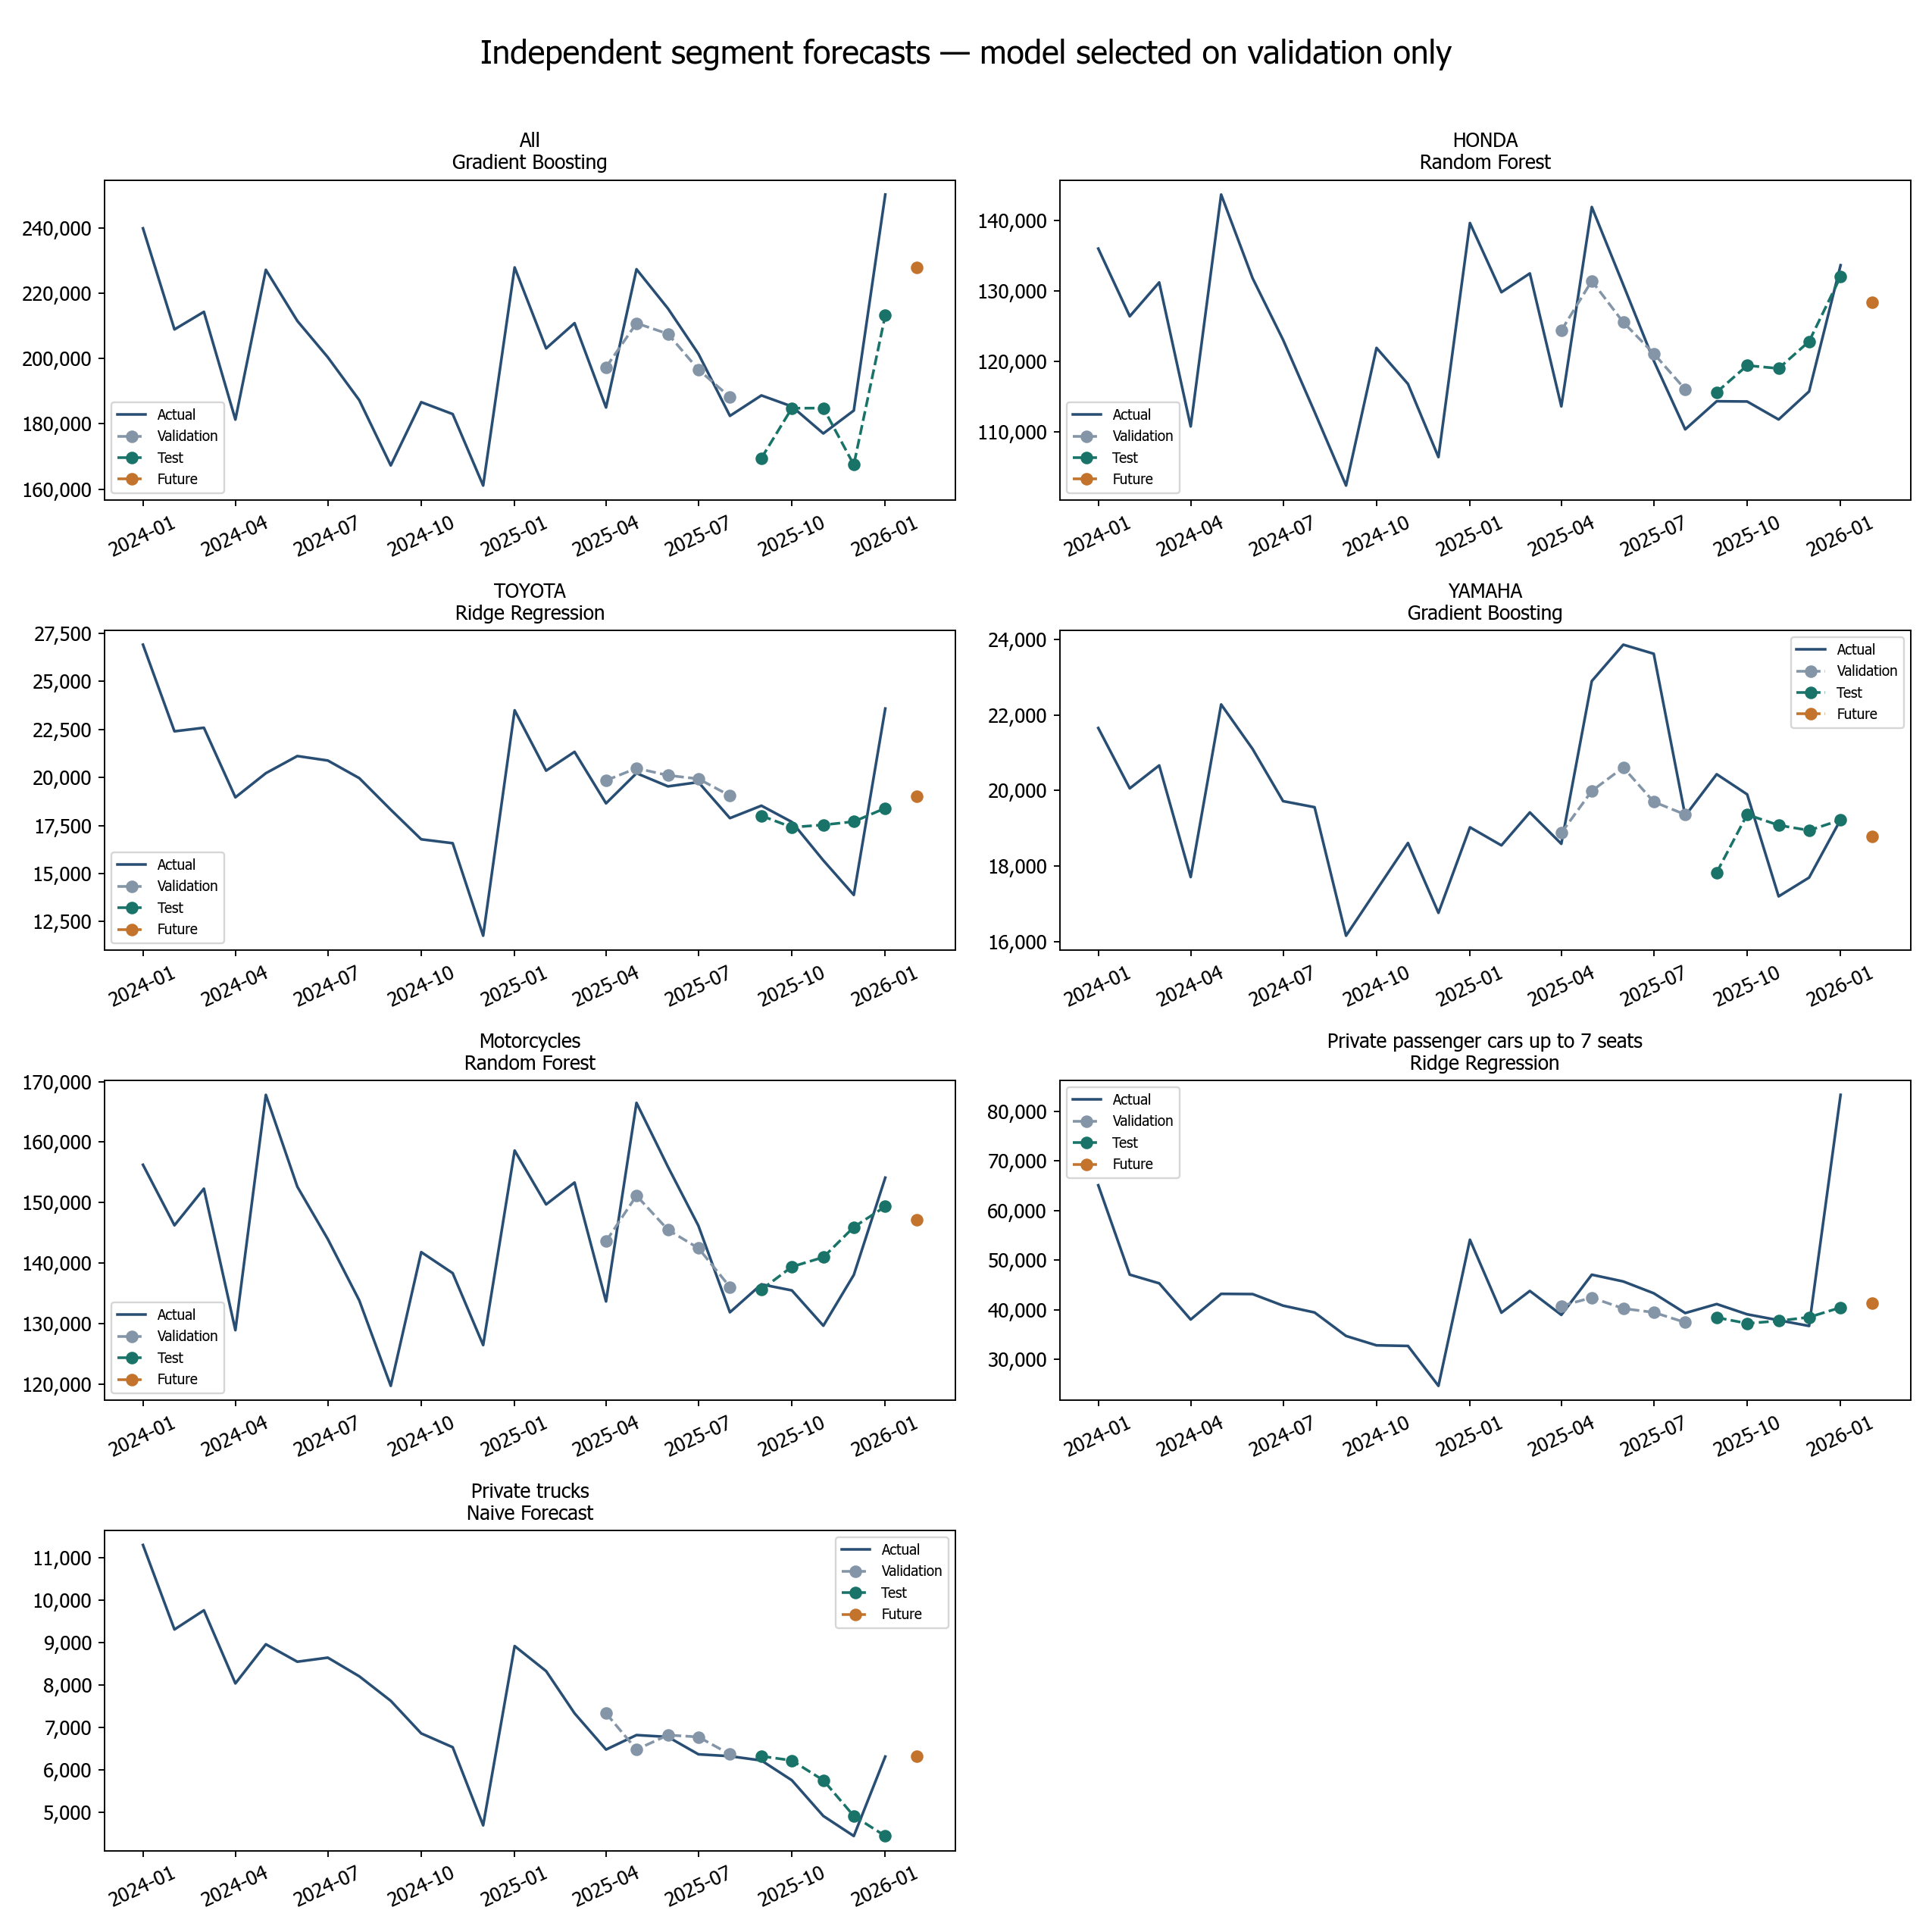

In [7]:
for name in ['brand_type_composition.png','validation_test_errors.png','segment_forecasts.png']:
    display(Image(filename=str(folder/name)))

## 8 ตรวจไฟล์ส่งและnullablefutureactual
บันทึกFact/Dimension, ETLcounts, dictionary, modelcomparison, forecast และhypothesesจากผลคำนวณจริง หน้าPowerBI5หน้า/8measures/3เทคนิค ยังต้องสร้างและตรวจในไฟล์.pbix รวมทั้งสมาชิกกลุ่มและtopicapproval

In [8]:
assert len(comparison)==35
assert len(forecast)==182
assert comparison.groupby('SeriesKey').SelectedModel.sum().eq(1).all()
assert forecast[forecast.DatasetSegment=='Future'].ActualRegistrations.isna().all()
assert forecast.groupby('SeriesKey').DatasetSegment.value_counts().unstack().eq(pd.Series({'History':15,'Validation':5,'Test':5,'Future':1})).all().all()
for name in ['FactRegistrations.csv','DimDate.csv','DimBrand.csv','DimVehicleType.csv','DimSeries.csv','FactForecast.csv','ModelComparison.csv','DataDictionary.csv','ETL_Counts.csv','HypothesisEvidence.csv']:
    path=folder/name
    assert path.exists()
    print(name,pd.read_csv(path).shape)
    display(FileLink(str(path)))

FactRegistrations.csv (5712, 5)


D:\Github\BI 2026\BI Term Project\FactRegistrations.csv

DimDate.csv (790, 7)


D:\Github\BI 2026\BI Term Project\DimDate.csv

DimBrand.csv (421, 2)


...

D:\Github\BI 2026\BI Term Project\DataDictionary.csv

ETL_Counts.csv (4, 4)


D:\Github\BI 2026\BI Term Project\ETL_Counts.csv

HypothesisEvidence.csv (6, 6)


D:\Github\BI 2026\BI Term Project\HypothesisEvidence.csv